# Garment order model comparison

This notebook runs the repository's canonical training pipeline, prints validation tables, and creates diagnostic and model comparison plots. It uses the shared project modules so the notebook and app use the same feature definitions.

## Before running

Open this notebook from the project folder and install the packages in `requirements.txt`. Running the training cell fits models and writes updated artifacts into `models/`; it does not change the source CSV files. TensorFlow is optional; `train.py` skips its DNN candidate when TensorFlow is unavailable. The checked-in data may be generated sample data, so replace it with verified factory records before treating scores as operational forecasts.

In [1]:
from pathlib import Path
import os
import json

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root even when Jupyter starts in a nested folder.
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "train.py").is_file() and (path / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook inside "
        "garment_order_system or one of its subfolders."
    )
os.chdir(PROJECT_ROOT)
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = MODEL_DIR / "plots"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "orders.csv", "allocations.csv", "interventions.csv", "workers.csv", "operations.csv"
]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing data files in {DATA_DIR}: {', '.join(missing_files)}")

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#fbfdff"})
print(f"Project: {PROJECT_ROOT}")
print(f"Data: {DATA_DIR}")
print(f"Plots will be saved to: {FIGURE_DIR}")

Project: d:\Research\V1\new6\Nadee
Data: d:\Research\V1\new6\Nadee\data
Plots will be saved to: d:\Research\V1\new6\Nadee\models\plots


## Inspect the source data

The notebook uses these CSV files as supplied. The checks below show row counts, required order fields, and outcome balance before the training pipeline starts.

In [2]:
orders = pd.read_csv(DATA_DIR / "orders.csv")
allocations = pd.read_csv(DATA_DIR / "allocations.csv")
interventions = pd.read_csv(DATA_DIR / "interventions.csv")

required_order_columns = {
    "order_id", "order_quantity", "handover_days", "required_smv_total",
    "order_value", "style_id", "priority", "on_time_flag", "n_available_workers",
    "n_shifts", "shift_hours", "actual_completed_qty", "order_date",
    "actual_completion_date",
}
missing_columns = sorted(required_order_columns - set(orders.columns))
if missing_columns:
    raise ValueError(f"data/orders.csv is missing columns required by train.py: {missing_columns}")

print(f"Orders: {len(orders):,} rows | {orders['order_id'].nunique():,} distinct orders")
print(f"Allocations: {len(allocations):,} rows | Interventions: {len(interventions):,} rows")
print("On-time outcome counts:")
display(orders["on_time_flag"].value_counts(dropna=False).rename_axis("on_time_flag").to_frame("orders"))
print("Shift count values in source orders:")
display(orders["n_shifts"].value_counts(dropna=False).sort_index().rename_axis("shifts").to_frame("orders"))

Orders: 3,000 rows | 3,000 distinct orders
Allocations: 19,382 rows | Interventions: 18,000 rows
On-time outcome counts:


,orders
on_time_flag,
1,2574
0,426


Shift count values in source orders:


,orders
shifts,
1,1481
2,1209
3,310


## Train and compare models

This runs `train.py`, the project's canonical pipeline. It compares the candidates with the same cross-validation definitions as the app's training workflow, then writes selected models and metrics under `models/`.

In [3]:
%run train.py

report_path = MODEL_DIR / "model_comparison.json"
if not report_path.is_file():
    raise FileNotFoundError("train.py completed without creating models/model_comparison.json")
with report_path.open(encoding="utf-8") as file:
    report = json.load(file)

print(report.get("data_note", ""))
print(f"Selected N1 order model: {report['N1_best']}")
print(f"Selected N2 intervention model: {report['N2_best']}")
print(f"Selected capacity model: {report['capacity_model']}")

  Training Logistic Regression...
  Training Random Forest...
  Training Extra Trees...
  Training Decision Tree...
  Training Gradient Boosting...
  Training Histogram Gradient Boosting...
  Training AdaBoost...
  Training K-Nearest Neighbors...
  Training Genetic Algorithm Neural Network (GANN)...
  Training Graph Neural Network (GNN)...
  Training Gaussian Naive Bayes...
  Training DNN (TensorFlow/Keras)...


On-time model comparison (sorted by Brier score, then ROC-AUC):
  DNN (TensorFlow/Keras)         Brier=0.0875  ROC-AUC=0.8494  F1=0.9312  <-- BEST
  Extra Trees                    Brier=0.0878  ROC-AUC=0.8555  F1=0.9326
  Logistic Regression            Brier=0.0879  ROC-AUC=0.8545  F1=0.9332
  Graph Neural Network (GNN)     Brier=0.0882  ROC-AUC=0.8430  F1=0.9347
  Gradient Boosting              Brier=0.0883  ROC-AUC=0.8498  F1=0.9316
  Genetic Algorithm Neural Network (GANN) Brier=0.0890  ROC-AUC=0.8393  F1=0.9326
  K-Nearest Neighbors            Brier=0.0891  ROC-AUC=0.8489  

## Plot helpers and source data diagnostics

These plots show the supplied data mix and the capacity targets produced by the shared capacity feature builder. They help reveal class imbalance, shift coverage, and unusually spread throughput records.

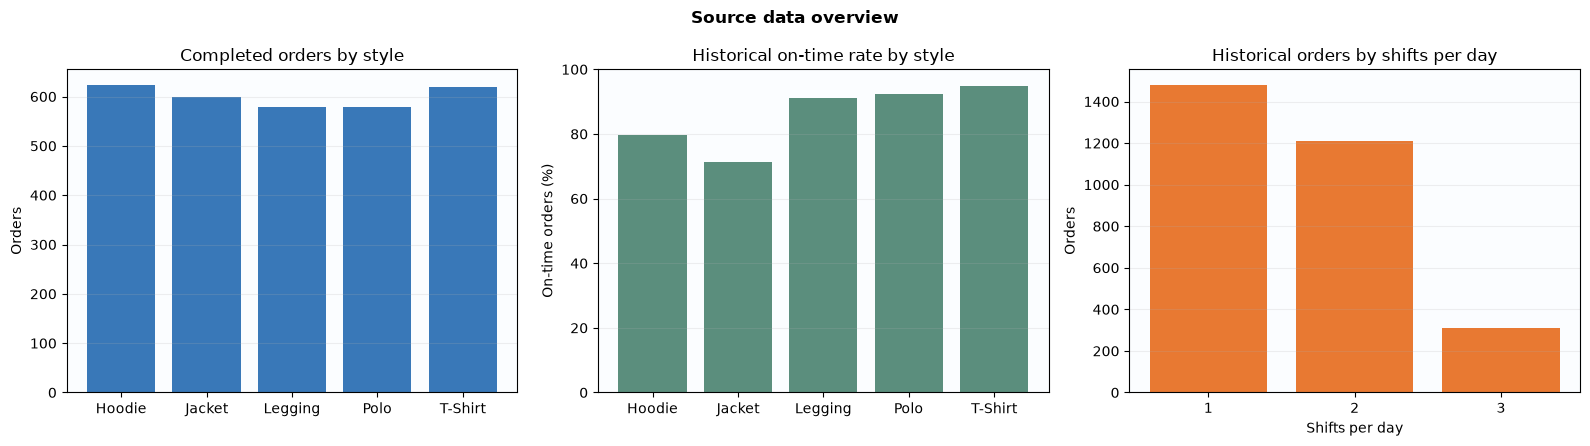

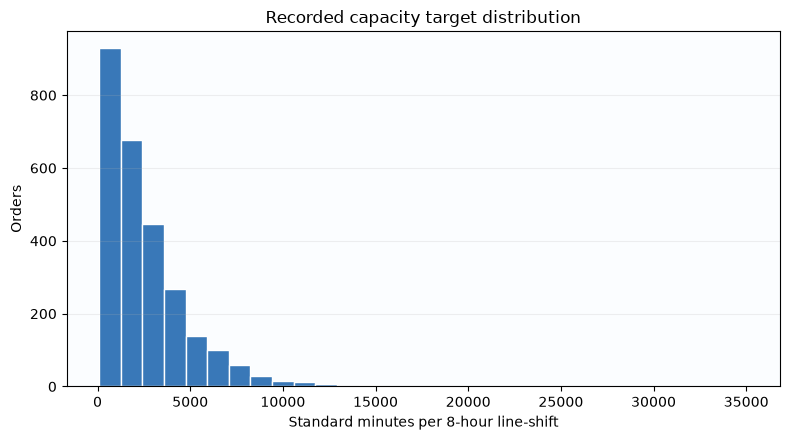

Valid capacity records: 2,690 across 2,690 orders


In [4]:
from capacity_model_features import build_capacity_training_data


def show_and_save(fig, filename):
    fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)


# Compare order mix, on-time outcome by style, and historical shift coverage.
style_counts = orders["style_id"].value_counts().sort_index()
on_time_by_style = orders.groupby("style_id")["on_time_flag"].mean().reindex(style_counts.index)
shift_counts = pd.to_numeric(orders["n_shifts"], errors="coerce").value_counts().sort_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(style_counts.index.astype(str), style_counts.values, color="#3978b8")
axes[0].set_title("Completed orders by style")
axes[0].set_ylabel("Orders")
axes[1].bar(on_time_by_style.index.astype(str), on_time_by_style.values * 100, color="#5b8e7d")
axes[1].set_title("Historical on-time rate by style")
axes[1].set_ylabel("On-time orders (%)")
axes[1].set_ylim(0, 100)
axes[2].bar(shift_counts.index.astype(str), shift_counts.values, color="#e87932")
axes[2].set_title("Historical orders by shifts per day")
axes[2].set_xlabel("Shifts per day")
axes[2].set_ylabel("Orders")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Source data overview", fontweight="bold")
fig.tight_layout()
show_and_save(fig, "01_source_data_overview.png")

X_capacity, y_capacity, capacity_groups, capacity_styles = build_capacity_training_data(orders)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(y_capacity, bins=30, color="#3978b8", edgecolor="white")
ax.set_title("Recorded capacity target distribution")
ax.set_xlabel("Standard minutes per 8-hour line-shift")
ax.set_ylabel("Orders")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
show_and_save(fig, "02_capacity_target_distribution.png")
print(f"Valid capacity records: {len(y_capacity):,} across {len(np.unique(capacity_groups)):,} orders")

## Classification model comparisons

N1 predicts an order's on-time outcome from order details. N2 predicts which recorded intervention scenario was selected. The plots compare out-of-fold ROC-AUC and Brier score; a lower Brier score indicates better probability calibration. The confusion matrices below use a 0.5 probability threshold.

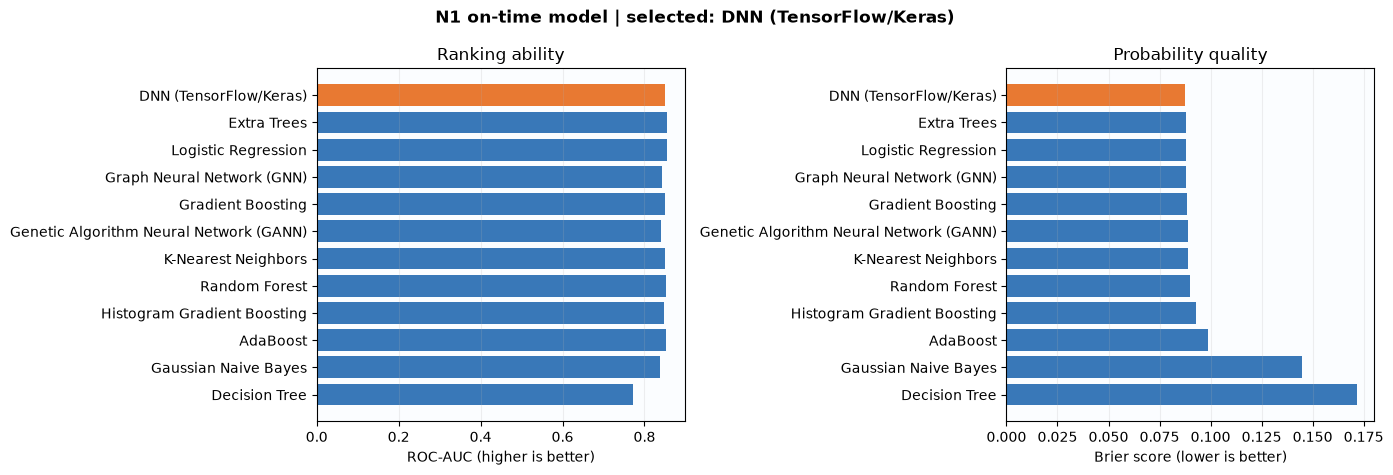

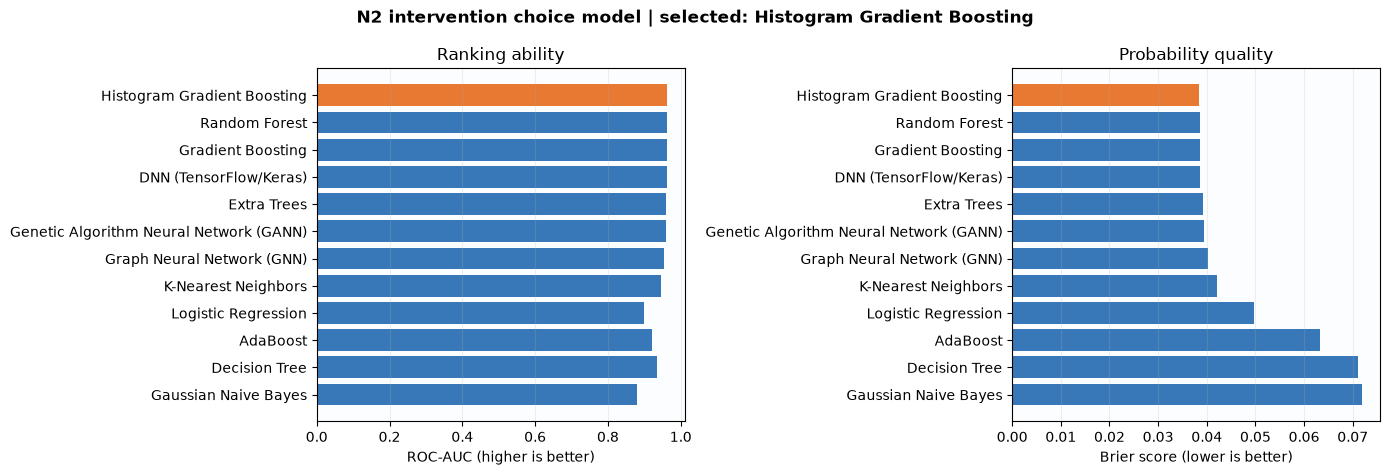

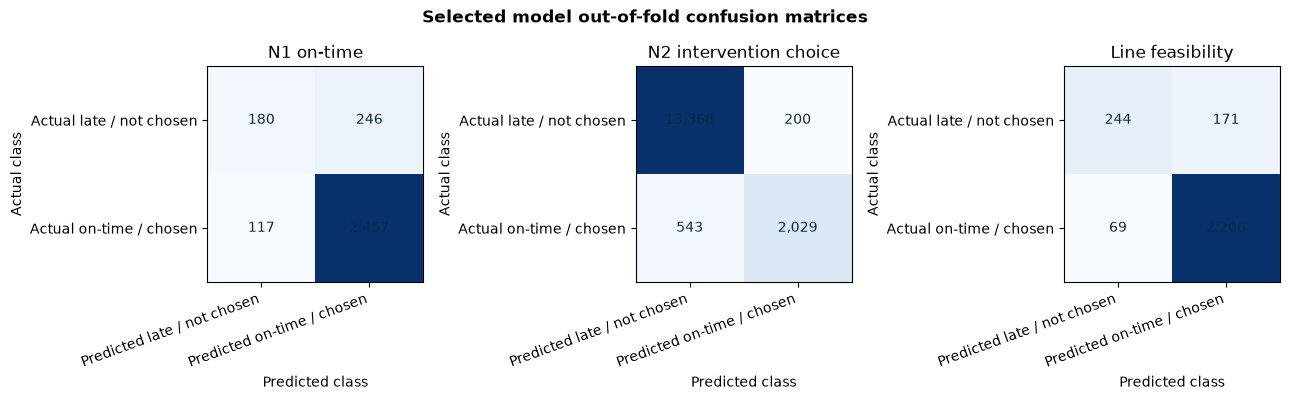

In [5]:
def plot_classifier_comparison(title, scores, selected_name, filename):
    ranked = sorted(scores.items(), key=lambda item: item[1]["brier_score"])
    names = [name for name, _ in ranked]
    auc = [values["roc_auc"] for _, values in ranked]
    brier = [values["brier_score"] for _, values in ranked]
    colors = ["#e87932" if name == selected_name else "#3978b8" for name in names]
    positions = np.arange(len(names))
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4.5, len(names) * 0.4)))
    for ax, values, label, heading in [
        (axes[0], auc, "ROC-AUC (higher is better)", "Ranking ability"),
        (axes[1], brier, "Brier score (lower is better)", "Probability quality"),
    ]:
        ax.barh(positions, values, color=colors)
        ax.set_yticks(positions, labels=names)
        ax.invert_yaxis()
        ax.set_xlabel(label)
        ax.set_title(heading)
        ax.grid(axis="x", alpha=0.2)
    fig.suptitle(f"{title} | selected: {selected_name}", fontweight="bold")
    fig.tight_layout()
    show_and_save(fig, filename)


plot_classifier_comparison("N1 on-time model", report["N1_models"], report["N1_best"], "03_n1_classifier_comparison.png")
plot_classifier_comparison("N2 intervention choice model", report["N2_models"], report["N2_best"], "04_n2_classifier_comparison.png")

confusion_items = [
    ("N1 on-time", report["N1_models"][report["N1_best"]]["confusion_matrix"]),
    ("N2 intervention choice", report["N2_models"][report["N2_best"]]["confusion_matrix"]),
    ("Line feasibility", report["line_model_metrics"]["confusion_matrix"]),
]
fig, axes = plt.subplots(1, len(confusion_items), figsize=(13, 4))
for ax, (title, matrix) in zip(axes, confusion_items):
    matrix = np.asarray(matrix, dtype=int)
    ax.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            ax.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center", color="#102a43")
    ax.set_xticks([0, 1], labels=["Predicted late / not chosen", "Predicted on-time / chosen"], rotation=20, ha="right")
    ax.set_yticks([0, 1], labels=["Actual late / not chosen", "Actual on-time / chosen"])
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
fig.suptitle("Selected model out-of-fold confusion matrices", fontweight="bold")
fig.tight_layout()
show_and_save(fig, "05_confusion_matrices.png")

## Intervention cost comparison

Cost models are ranked by mean absolute error (MAE). R² is shown alongside MAE as a secondary fit measure; negative R² means a model performed worse than predicting the mean on those validation folds.

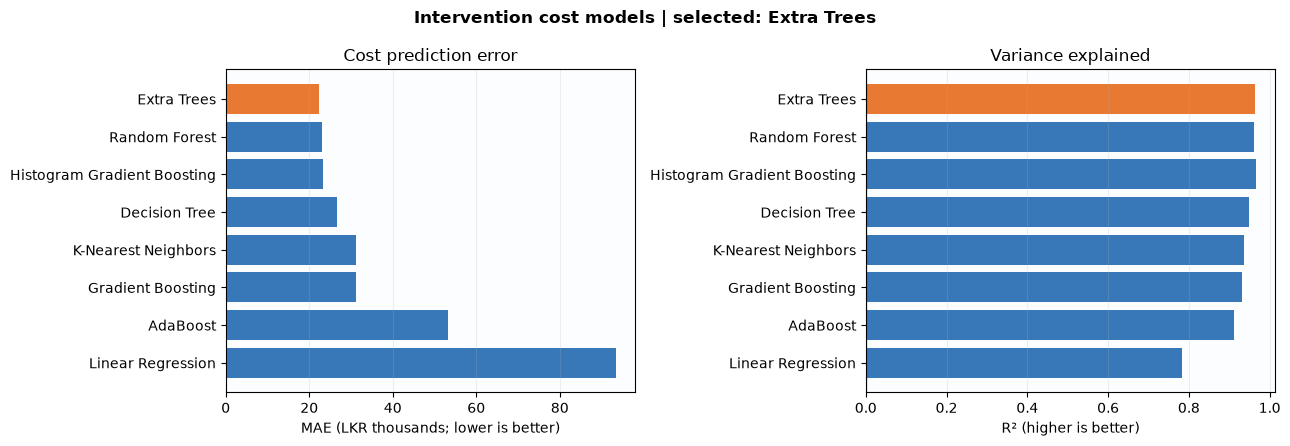

In [6]:
cost_scores = report["cost_models"]
cost_names = sorted(cost_scores, key=lambda name: cost_scores[name]["mae"])
positions = np.arange(len(cost_names))
colors = ["#e87932" if name == report["cost_best"] else "#3978b8" for name in cost_names]
fig, axes = plt.subplots(1, 2, figsize=(13, max(4.5, len(cost_names) * 0.42)))
axes[0].barh(positions, [cost_scores[name]["mae"] / 1000 for name in cost_names], color=colors)
axes[0].set_yticks(positions, labels=cost_names)
axes[0].invert_yaxis()
axes[0].set_xlabel("MAE (LKR thousands; lower is better)")
axes[0].set_title("Cost prediction error")
axes[0].grid(axis="x", alpha=0.2)
axes[1].barh(positions, [cost_scores[name]["r2"] for name in cost_names], color=colors)
axes[1].set_yticks(positions, labels=cost_names)
axes[1].invert_yaxis()
axes[1].axvline(0, color="#102a43", linewidth=0.8)
axes[1].set_xlabel("R² (higher is better)")
axes[1].set_title("Variance explained")
axes[1].grid(axis="x", alpha=0.2)
fig.suptitle(f"Intervention cost models | selected: {report['cost_best']}", fontweight="bold")
fig.tight_layout()
show_and_save(fig, "06_intervention_cost_comparison.png")

## Worker-operation performance comparison

N4 predicts efficiency and quality from recorded worker-operation attributes. These metrics are not a live worker roster or named assignment recommendation.

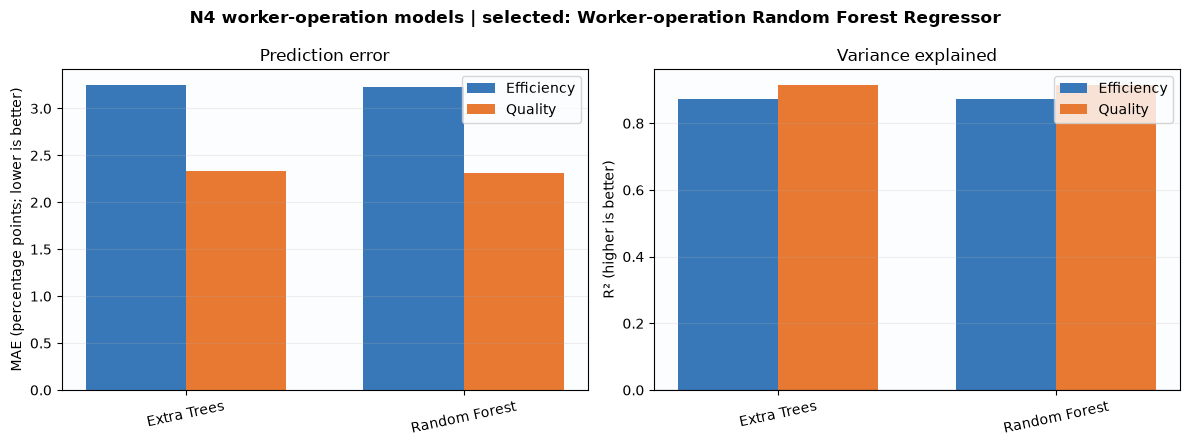

In [7]:
workforce_scores = report["workforce_models"]
workforce_names = list(workforce_scores)
positions = np.arange(len(workforce_names))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(positions - width / 2, [workforce_scores[name]["efficiency_mae"] for name in workforce_names], width, label="Efficiency", color="#3978b8")
axes[0].bar(positions + width / 2, [workforce_scores[name]["quality_mae"] for name in workforce_names], width, label="Quality", color="#e87932")
axes[0].set_xticks(positions, labels=workforce_names, rotation=12)
axes[0].set_ylabel("MAE (percentage points; lower is better)")
axes[0].set_title("Prediction error")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)
axes[1].bar(positions - width / 2, [workforce_scores[name]["efficiency_r2"] for name in workforce_names], width, label="Efficiency", color="#3978b8")
axes[1].bar(positions + width / 2, [workforce_scores[name]["quality_r2"] for name in workforce_names], width, label="Quality", color="#e87932")
axes[1].axhline(0, color="#102a43", linewidth=0.8)
axes[1].set_xticks(positions, labels=workforce_names, rotation=12)
axes[1].set_ylabel("R² (higher is better)")
axes[1].set_title("Variance explained")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)
fig.suptitle(f"N4 worker-operation models | selected: {report['workforce_model']}", fontweight="bold")
fig.tight_layout()
show_and_save(fig, "07_workforce_model_comparison.png")

## Production capacity comparison

N5 predicts completed standard garment minutes per staffed 8-hour line-shift. MAE is the model-selection metric. This aggregate target does not provide line-specific or shift-specific output rates.

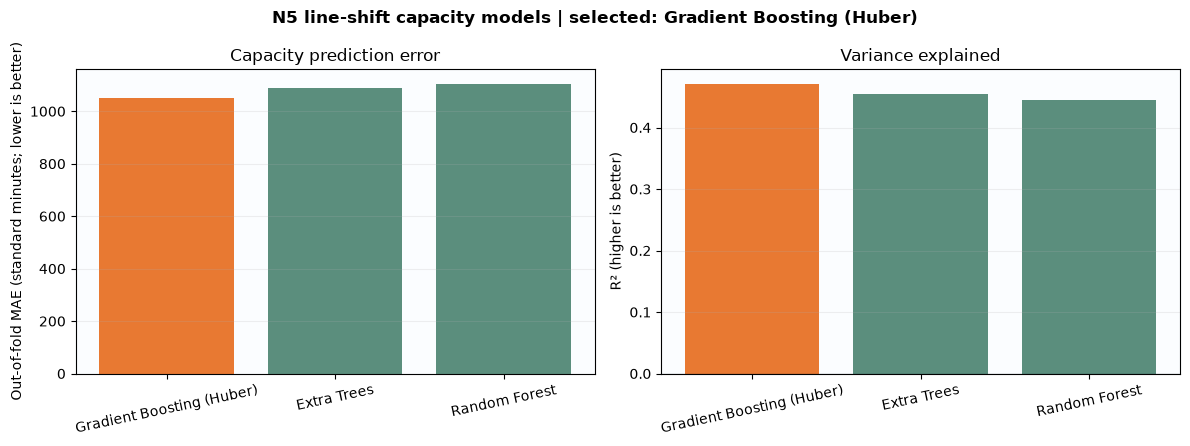

In [8]:
capacity_scores = report["capacity_model_candidates"]
capacity_names = sorted(capacity_scores, key=lambda name: capacity_scores[name]["mae_standard_minutes_per_line_shift"])
positions = np.arange(len(capacity_names))
colors = ["#e87932" if name == report["capacity_model"] else "#5b8e7d" for name in capacity_names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(positions, [capacity_scores[name]["mae_standard_minutes_per_line_shift"] for name in capacity_names], color=colors)
axes[0].set_xticks(positions, labels=capacity_names, rotation=12)
axes[0].set_ylabel("Out-of-fold MAE (standard minutes; lower is better)")
axes[0].set_title("Capacity prediction error")
axes[0].grid(axis="y", alpha=0.2)
axes[1].bar(positions, [capacity_scores[name]["r2"] for name in capacity_names], color=colors)
axes[1].axhline(0, color="#102a43", linewidth=0.8)
axes[1].set_xticks(positions, labels=capacity_names, rotation=12)
axes[1].set_ylabel("R² (higher is better)")
axes[1].set_title("Variance explained")
axes[1].grid(axis="y", alpha=0.2)
fig.suptitle(f"N5 line-shift capacity models | selected: {report['capacity_model']}", fontweight="bold")
fig.tight_layout()
show_and_save(fig, "08_capacity_model_comparison.png")

## Validation tables

The tables contain out-of-fold results from `train.py`. Scores compare these candidates on the supplied records; they do not guarantee future order performance.

In [9]:
def show_metric_table(title, values, sort_by=None):
    table = pd.DataFrame(values).T
    if sort_by and sort_by in table.columns:
        table = table.sort_values(sort_by)
    table.index.name = title
    display(table)


print(f"Training orders: {report['training_orders']:,}")
print(f"N2 scenario orders: {report['N2_training_orders']:,}")
print(f"N4 completed allocations: {report['workforce_training_allocations']:,}")
print(f"N5 capacity orders: {report['capacity_model_training_orders']:,}")
show_metric_table("N1 on-time model", report["N1_models"], "brier_score")
show_metric_table("N2 intervention choice model", report["N2_models"], "brier_score")
show_metric_table("Intervention cost model", report["cost_models"], "mae")
show_metric_table("Line feasibility model", {report["line_model"]: report["line_model_metrics"]})
show_metric_table("N4 workforce model", report["workforce_models"])
show_metric_table("N5 capacity model", report["capacity_model_candidates"], "mae_standard_minutes_per_line_shift")
print(f"Plot files: {FIGURE_DIR}")

Training orders: 3,000
N2 scenario orders: 2,690
N4 completed allocations: 13,659
N5 capacity orders: 2,690


,accuracy,precision,recall,f1,roc_auc,brier_score,confusion_matrix
N1 on-time model,,,,,,,
DNN (TensorFlow/Keras),0.879,0.909,0.9545,0.9312,0.8494,0.0875,"[[180, 246], [117, 2457]]"
Extra Trees,0.8797,0.8982,0.9697,0.9326,0.8555,0.0878,"[[143, 283], [78, 2496]]"
Logistic Regression,0.8807,0.8974,0.972,0.9332,0.8545,0.0879,"[[140, 286], [72, 2502]]"
Graph Neural Network (GNN),0.8837,0.9018,0.9701,0.9347,0.843,0.0882,"[[154, 272], [77, 2497]]"
Gradient Boosting,0.8777,0.8957,0.9705,0.9316,0.8498,0.0883,"[[135, 291], [76, 2498]]"
Genetic Algorithm Neural Network (GANN),0.88,0.8996,0.9681,0.9326,0.8393,0.089,"[[148, 278], [82, 2492]]"
K-Nearest Neighbors,0.879,0.8975,0.9697,0.9322,0.8489,0.0891,"[[141, 285], [78, 2496]]"
Random Forest,0.878,0.9003,0.9646,0.9314,0.8527,0.0901,"[[151, 275], [91, 2483]]"
Histogram Gradient Boosting,0.8687,0.8964,0.9577,0.926,0.8469,0.0928,"[[141, 285], [109, 2465]]"


,accuracy,precision,recall,f1,roc_auc,brier_score,confusion_matrix
N2 intervention choice model,,,,,,,
Histogram Gradient Boosting,0.954,0.9103,0.7889,0.8452,0.9623,0.0385,"[[13368, 200], [543, 2029]]"
Random Forest,0.9535,0.9114,0.7842,0.8431,0.9618,0.0386,"[[13372, 196], [555, 2017]]"
Gradient Boosting,0.9537,0.9039,0.7935,0.8451,0.9618,0.0386,"[[13351, 217], [531, 2041]]"
DNN (TensorFlow/Keras),0.9538,0.9083,0.7897,0.8448,0.9618,0.0387,"[[13363, 205], [541, 2031]]"
Extra Trees,0.9535,0.9038,0.7924,0.8444,0.9594,0.0392,"[[13351, 217], [534, 2038]]"
Genetic Algorithm Neural Network (GANN),0.9528,0.9136,0.7772,0.8399,0.9589,0.0394,"[[13379, 189], [573, 1999]]"
Graph Neural Network (GNN),0.9525,0.9082,0.7807,0.8396,0.9542,0.0402,"[[13365, 203], [564, 2008]]"
K-Nearest Neighbors,0.9501,0.8918,0.7819,0.8332,0.947,0.0422,"[[13324, 244], [561, 2011]]"
Logistic Regression,0.9431,0.8161,0.8297,0.8228,0.8994,0.0496,"[[13087, 481], [438, 2134]]"


,mae,r2
Intervention cost model,,
Extra Trees,22361.30,0.9640
Random Forest,23005.27,0.9619
Histogram Gradient Boosting,23264.48,0.9653
Decision Tree,26642.39,0.9478
K-Nearest Neighbors,31188.34,0.9366
Gradient Boosting,31275.61,0.9316
AdaBoost,53323.20,0.9124
Linear Regression,93356.75,0.7820


,accuracy,precision,recall,f1,roc_auc,brier_score,confusion_matrix
Line feasibility model,,,,,,,
Line-aware Logistic Regression,0.9108,0.9281,0.9697,0.9484,0.9119,0.0655,"[[244, 171], [69, 2206]]"


,efficiency_mae,efficiency_r2,quality_mae,quality_r2
N4 workforce model,,,,
Extra Trees,3.254,0.8723,2.333,0.9147
Random Forest,3.232,0.8741,2.316,0.9161


,mae_standard_minutes_per_line_shift,r2
N5 capacity model,,
Gradient Boosting (Huber),1049.647,0.4711
Extra Trees,1089.973,0.4539
Random Forest,1104.699,0.4453


Plot files: d:\Research\V1\new6\Nadee\models\plots


## How to interpret the results

- The lowest Brier score selects N1 and N2; ROC-AUC breaks ties. The classification plots show these out-of-fold comparisons.
- N2 learns which intervention scenario was selected in the supplied records. It does not estimate causal delivery improvement.
- Cost MAE is in the same currency units as `interventions.csv` (`total_cost`, expected LKR); check that the input costs are current and correctly recorded.
- N3's line-feasibility estimate uses historical staffing and two-shift assumptions. It does not verify live attendance or machine availability.
- N4 learns from completed worker-operation records. It does not assign named workers.
- N5 predicts pooled line-shift throughput from order-level records. Equal rates across lines or shifts cannot be inferred from this dataset.
- If the checked-in CSVs are generated sample data, replace them with verified factory history before making production commitments.

Figures are displayed inline and saved as PNG files in `models/plots/`. The generated model and metrics artifacts are written under `models/`.